In [1]:
from df_generate import prepare_df
from collections import Counter
import random


TOPOLOGY_CODES = {
    "process_centric": "T1",
    "file_centric": "T2",
    "socket_centric": "T3",
    "balanced_connector": "T4",
}

COMMUNICATION_CODES = {
    "spawner": "C1",
    "modifier": "C2",
    "read_dominant": "C3",
    "write_dominant": "C4",
    "read_write": "C5",
    "send_dominant": "C6",
    "receive_dominant": "C7",
    "bidirectional": "C8",
    "mixed_communication": "C9",
}

from collections import Counter
import random
import os
import statistics


def generate_balanced(dataset, seed=42):
    dfs = prepare_df(dataset)

    uuid_beh = {}

    for _, row in dfs.iterrows():
        uuid_beh[row["uuid"]] = (
            TOPOLOGY_CODES[row["topology_label"]]
            + "-"
            + COMMUNICATION_CODES[row["communication_label"]]
        )

    # Count number of UUIDs for each behavioral profile
    profile_counts = Counter(uuid_beh.values())

    # Calculate median profile size
    median_count = statistics.median(profile_counts.values())

    print(f"\nDataset: {dataset}")
    print(f"Number of profiles: {len(profile_counts)}")
    print(f"Median profile size: {median_count}")

    os.makedirs("./filters", exist_ok=True)
    removelist = set()

    # Process profiles in descending order of frequency
    for profile, num in profile_counts.most_common():

        if num > median_count:

            # Number of nodes that should be removed
            remove_count = int(num - median_count)

            # Get UUIDs belonging to this profile
            profile_uuids = [
                uuid
                for uuid, value in uuid_beh.items()
                if value == profile
            ]

            # Randomly select nodes to remove
            rng = random.Random(seed)
            selected_uuids = rng.sample(profile_uuids, remove_count)

            print(
                f"{profile}: "
                f"{num} -> {int(median_count)} "
                f"(remove {remove_count})"
            )
            removelist.update(set(selected_uuids))
            # Save UUIDs to remove
    print(f'{dataset} : {len(removelist)/len(uuid_beh)}')
    with open( f"./filters/{dataset}_balanced.txt", "w" ) as f:
            for uuid in removelist:
                f.write(uuid + "\n")

def generate_sample (dataset):
    dfs = prepare_df(dataset)
    uuid_beh = {}
    for _, row in dfs.iterrows():
        uuid_beh[row["uuid"]] = TOPOLOGY_CODES[row["topology_label"]] + '-' + COMMUNICATION_CODES[row["communication_label"]]

    top_3 = Counter(uuid_beh.values()).most_common(3)

    count = 0
    for key , num in top_3 :
        print(f'{key}  {num}  {num/len(uuid_beh)}')
        count+=1
        with open(f'./filters/{dataset}_{count}.txt' ,'w') as f:
            for uuid , value in uuid_beh.items():
                if value == key:
                    f.write(uuid+'\n') 

    uuid_beh = uuid_beh.keys()
    sample_size = int(len(uuid_beh)*0.25)
    fil_75 = set(random.sample(list(uuid_beh), k = sample_size))
    uuid_beh = uuid_beh -fil_75
    fil_50 = set(random.sample(list(uuid_beh), k = sample_size))
    uuid_beh = uuid_beh -fil_50
    fil_25 = set(random.sample(list(uuid_beh), k = sample_size))
    with open(f'./filters/{dataset}_75.txt' ,'w') as f:
        for x in fil_75:
            f.write(x+'\n') 
    with open(f'./filters/{dataset}_50.txt' ,'w') as f:
        for x in fil_50:
            f.write(x+'\n') 
    with open(f'./filters/{dataset}_25.txt' ,'w') as f:
        for x in fil_25:
            f.write(x+'\n') 

def generate_sample_count (dataset , size1 , size2, size3):
    dfs = prepare_df(dataset)
    uuid_beh = {}
    for _, row in dfs.iterrows():
        uuid_beh[row["uuid"]] = TOPOLOGY_CODES[row["topology_label"]] + '-' + COMMUNICATION_CODES[row["communication_label"]]

    uuid_beh = uuid_beh.keys()

    fil_1 = set(random.sample(list(uuid_beh), k = size1))
    fil_2 = set(random.sample(list(uuid_beh), k = size2))
    fil_3 = set(random.sample(list(uuid_beh), k = size3))
    with open(f'./filters/{dataset}_1_random.txt' ,'w') as f:
        for x in fil_1:
            f.write(x+'\n') 
    with open(f'./filters/{dataset}_2_random.txt' ,'w') as f:
        for x in fil_2:
            f.write(x+'\n') 
    with open(f'./filters/{dataset}_3_random.txt' ,'w') as f:
        for x in fil_3:
            f.write(x+'\n') 




In [7]:
generate_sample('theia-e3')


(402164, 14)
Loading Nodes ...
file_00000.parquet                246,074
netflow_00000.parquet              69,870
subject_00000.parquet              92,375
------------------------------------------
Loaded Nodes : 408,319
63452
59309
T2-C3  19132  0.3737594748769243
T4-C9  15554  0.3038602797530671
T4-C3  6205  0.12121981714464328


In [3]:
generate_sample_count('theia-e3' , 19132,15554,6205)

Loading Nodes ...
[WindowsPath('process_result/theia-e3/nodes/file_00000.parquet'), WindowsPath('process_result/theia-e3/nodes/netflow_00000.parquet'), WindowsPath('process_result/theia-e3/nodes/subject_00000.parquet')]
file_00000.parquet                246,074
netflow_00000.parquet              69,870
subject_00000.parquet              92,375
------------------------------------------
Loaded Nodes : 408,319


In [2]:
generate_sample('theia-e5')

(988191, 14)
Loading Nodes ...
file_00000.parquet                615,015
netflow_00000.parquet              12,748
subject_00000.parquet             383,374
------------------------------------------
Loaded Nodes : 1,011,137
352589
351738
T4-C4  218673  0.6527805556633541
T4-C5  60744  0.1813324099144146
T1-C1  43289  0.1292259102592041


In [5]:
generate_sample_count('theia-e5' , 218673 , 60744 , 43289)

Loading Nodes ...
[WindowsPath('process_result/theia-e5/nodes/file_00000.parquet'), WindowsPath('process_result/theia-e5/nodes/netflow_00000.parquet'), WindowsPath('process_result/theia-e5/nodes/subject_00000.parquet')]
file_00000.parquet                615,015
netflow_00000.parquet              12,748
subject_00000.parquet             383,374
------------------------------------------
Loaded Nodes : 1,011,137


In [6]:
generate_sample('trace-e3')

(9424053, 14)
Loading Nodes ...
file_00000.parquet                197,598
netflow_00000.parquet             483,461
subject_00000.parquet           1,000,000
subject_00001.parquet           1,000,000
subject_00002.parquet           1,000,000
subject_00003.parquet           1,000,000
subject_00004.parquet           1,000,000
subject_00005.parquet           1,000,000
subject_00006.parquet           1,000,000
subject_00007.parquet           1,000,000
subject_00008.parquet           1,000,000
subject_00009.parquet              98,554
------------------------------------------
Loaded Nodes : 9,779,613
37705
35614
T2-C3  9578  0.3170263471468291
T3-C8  9104  0.3013372169998676
T2-C2  4800  0.15887726731100224


In [6]:
generate_sample_count('trace-e3' , 9578 ,9104,4800)

Loading Nodes ...
[WindowsPath('process_result/trace-e3/nodes/file_00000.parquet'), WindowsPath('process_result/trace-e3/nodes/netflow_00000.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00000.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00001.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00002.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00003.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00004.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00005.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00006.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00007.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00008.parquet'), WindowsPath('process_result/trace-e3/nodes/subject_00009.parquet')]
file_00000.parquet                197,598
netflow_00000.parquet             483,461
subject_00000.parquet           1,000,000
subject_00001.parquet           1,000,000


In [7]:
generate_sample('trace-e5')

(2891040, 14)
Loading Nodes ...
file_00000.parquet                348,620
netflow_00000.parquet             427,890
subject_00000.parquet           1,000,000
subject_00001.parquet           1,000,000
subject_00002.parquet             528,472
------------------------------------------
Loaded Nodes : 3,304,982
56786
55274
T1-C1  36107  0.681843074308375
T4-C1  5796  0.10945142101784534
T2-C2  2799  0.052856198659238976


In [8]:
generate_sample_count('trace-e5' , 36107 , 5796 , 2799 )

Loading Nodes ...
[WindowsPath('process_result/trace-e5/nodes/file_00000.parquet'), WindowsPath('process_result/trace-e5/nodes/netflow_00000.parquet'), WindowsPath('process_result/trace-e5/nodes/subject_00000.parquet'), WindowsPath('process_result/trace-e5/nodes/subject_00001.parquet'), WindowsPath('process_result/trace-e5/nodes/subject_00002.parquet')]
file_00000.parquet                348,620
netflow_00000.parquet             427,890
subject_00000.parquet           1,000,000
subject_00001.parquet           1,000,000
subject_00002.parquet             528,472
------------------------------------------
Loaded Nodes : 3,304,982


In [3]:
generate_balanced('theia-e3')
generate_balanced('theia-e5')
generate_balanced('trace-e3')
generate_balanced('trace-e5')

Loading Nodes ...
[WindowsPath('process_result/theia-e3/nodes/file_00000.parquet'), WindowsPath('process_result/theia-e3/nodes/netflow_00000.parquet'), WindowsPath('process_result/theia-e3/nodes/subject_00000.parquet')]
file_00000.parquet                246,074
netflow_00000.parquet              69,870
subject_00000.parquet              92,375
------------------------------------------
Loaded Nodes : 408,319

Dataset: theia-e3
Number of profiles: 9
Median profile size: 2993
T2-C3: 19132 -> 2993 (remove 16139)
T4-C9: 15554 -> 2993 (remove 12561)
T4-C3: 6205 -> 2993 (remove 3212)
T4-C5: 3818 -> 2993 (remove 825)
theia-e3 : 0.6395444244744862
Loading Nodes ...
[WindowsPath('process_result/theia-e5/nodes/file_00000.parquet'), WindowsPath('process_result/theia-e5/nodes/netflow_00000.parquet'), WindowsPath('process_result/theia-e5/nodes/subject_00000.parquet')]
file_00000.parquet                615,015
netflow_00000.parquet              12,748
subject_00000.parquet             383,374
------

In [8]:
import os
import math


def split_file(filename, parts):
    with open(filename, "r", encoding="utf-8") as f:
        lines = f.readlines()

    total_lines = len(lines)
    lines_per_part = math.ceil(total_lines / parts)

    name, ext = os.path.splitext(filename)

    for i in range(parts):
        start = i * lines_per_part
        end = min(start + lines_per_part, total_lines)

        if start >= total_lines:
            break

        output_file = f"{name}_part{i + 1}{ext}"

        with open(output_file, "w", encoding="utf-8") as f:
            f.writelines(lines[start:end])

        print(f"{output_file}: {end - start} lines")




split_file('./filters/theia-e5_balanced.txt', 4)

./filters/theia-e5_balanced_part1.txt: 75735 lines
./filters/theia-e5_balanced_part2.txt: 75735 lines
./filters/theia-e5_balanced_part3.txt: 75735 lines
./filters/theia-e5_balanced_part4.txt: 75734 lines


In [2]:
import os
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
from df_generate import prepare_df
from collections import Counter

def get_result(dataset , data_dic):
 
    data_dic[dataset] ={}



    dfs = prepare_df(dataset)

    uuid_beh = {}

    for _, row in dfs.iterrows():
        uuid_beh[row["uuid"]] = (
            TOPOLOGY_CODES[row["topology_label"]]
            + "-"
            + COMMUNICATION_CODES[row["communication_label"]]
        )




    original_counts, total = Counter(uuid_beh.values()), len(uuid_beh)
    data_dic[dataset]["original_counts"] = original_counts
    data_dic[dataset]["original_total"] = total

    filter_file = f"./filters/{dataset}_balanced.txt"

    if not os.path.exists(filter_file):
        raise FileNotFoundError(filter_file)

    with open(filter_file, "r") as f:
        removed_uuids = {line.strip() for line in f}


    # Remove balanced UUIDs
    balanced_uuid_beh = {
        uuid: profile
        for uuid, profile in uuid_beh.items()
        if uuid not in removed_uuids
    }

    balanced_counts = Counter(balanced_uuid_beh.values())
    data_dic[dataset]["balanced_counts"] = balanced_counts
    data_dic[dataset]["balanced_total"] = len(balanced_uuid_beh)

    return data_dic

datasets = [
    "theia-e3",
    "theia-e5",
    "trace-e3",
    "trace-e5"
]
data_dic = {}
for x in datasets:
    data_dic = get_result(x , data_dic)




Loading Nodes ...
[WindowsPath('process_result/theia-e3/nodes/file_00000.parquet'), WindowsPath('process_result/theia-e3/nodes/netflow_00000.parquet'), WindowsPath('process_result/theia-e3/nodes/subject_00000.parquet')]
file_00000.parquet                246,074
netflow_00000.parquet              69,870
subject_00000.parquet              92,375
------------------------------------------
Loaded Nodes : 408,319
Loading Nodes ...
[WindowsPath('process_result/theia-e5/nodes/file_00000.parquet'), WindowsPath('process_result/theia-e5/nodes/netflow_00000.parquet'), WindowsPath('process_result/theia-e5/nodes/subject_00000.parquet')]
file_00000.parquet                615,015
netflow_00000.parquet              12,748
subject_00000.parquet             383,374
------------------------------------------
Loaded Nodes : 1,011,137
Loading Nodes ...
[WindowsPath('process_result/trace-e3/nodes/file_00000.parquet'), WindowsPath('process_result/trace-e3/nodes/netflow_00000.parquet'), WindowsPath('process_r

In [15]:
data_dic

{'theia-e3': {'original_counts': Counter({'T2-C3': 19132,
           'T4-C9': 15554,
           'T4-C3': 6205,
           'T4-C5': 3818,
           'T4-C8': 2993,
           'T2-C5': 1579,
           'T2-C9': 1181,
           'T1-C1': 464,
           'T3-C8': 262}),
  'original_total': 51188,
  'balanced_counts': Counter({'T4-C3': 2993,
           'T4-C5': 2993,
           'T2-C3': 2993,
           'T4-C8': 2993,
           'T4-C9': 2993,
           'T2-C5': 1579,
           'T2-C9': 1181,
           'T1-C1': 464,
           'T3-C8': 262}),
  'balanced_total': 18451},
 'theia-e5': {'original_counts': Counter({'T4-C4': 218673,
           'T4-C5': 60744,
           'T1-C1': 43289,
           'T4-C3': 6589,
           'T4-C9': 2697,
           'T4-C1': 2521,
           'T2-C3': 474}),
  'original_total': 334987,
  'balanced_counts': Counter({'T1-C1': 6589,
           'T4-C3': 6589,
           'T4-C4': 6589,
           'T4-C5': 6589,
           'T4-C9': 2697,
           'T4-C1': 2521,
    

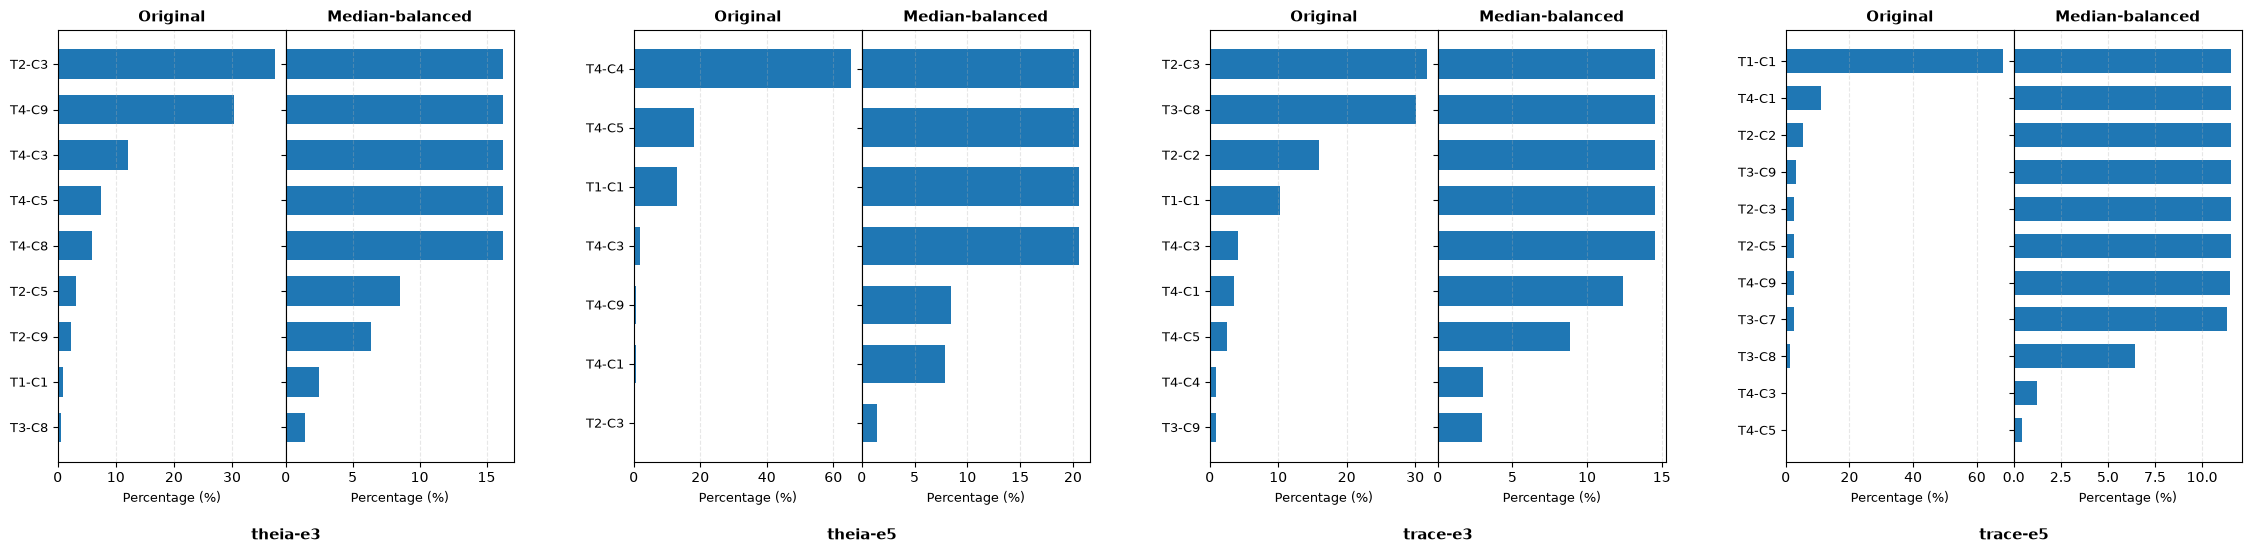

In [14]:
import matplotlib.pyplot as plt
import numpy as np


# فاصله‌ی بین جفت‌ها بیشتر از فاصله‌ی داخل هر جفت
fig = plt.figure(figsize=(24, 6))

# موقعیت دستی 8 نمودار
# هر جفت: Original + Median-balanced
positions = [
    (0.03,  0.15, 0.095, 0.72),  # theia-e3 Original
    (0.125, 0.15, 0.095, 0.72),  # theia-e3 Balanced

    (0.27,  0.15, 0.095, 0.72),  # theia-e5 Original
    (0.365, 0.15, 0.095, 0.72),  # theia-e5 Balanced

    (0.51,  0.15, 0.095, 0.72),  # trace-e3 Original
    (0.605, 0.15, 0.095, 0.72),  # trace-e3 Balanced

    (0.75,  0.15, 0.095, 0.72),  # trace-e5 Original
    (0.845, 0.15, 0.095, 0.72),  # trace-e5 Balanced
]

axes = []

for pos in positions:
    axes.append(fig.add_axes(pos))


for i, dataset in enumerate(datasets):

    data = data_dic[dataset]

    original = data["original_counts"]
    original_total = data["original_total"]

    balanced = data["balanced_counts"]
    balanced_total = data["balanced_total"]

    # Profileها را بر اساس Original مرتب می‌کنیم
    profiles = sorted(
        original.keys(),
        key=lambda x: original[x],
        reverse=True
    )

    original_pct = [
        100 * original.get(p, 0) / original_total
        for p in profiles
    ]

    balanced_pct = [
        100 * balanced.get(p, 0) / balanced_total
        for p in profiles
    ]

    y = np.arange(len(profiles))

    ax1 = axes[2 * i]
    ax2 = axes[2 * i + 1]

    # =========================
    # Original
    # =========================
    ax1.barh(
        y,
        original_pct,
        height=0.65
    )

    ax1.set_yticks(y)
    ax1.set_yticklabels(
        profiles,
        fontsize=9
    )

    ax1.invert_yaxis()

    ax1.set_title(
        "Original",
        fontsize=11,
        fontweight="bold"
    )

    ax1.set_xlabel(
        "Percentage (%)",
        fontsize=9
    )

    ax1.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    # =========================
    # Median-balanced
    # =========================
    ax2.barh(
        y,
        balanced_pct,
        height=0.65
    )

    ax2.set_yticks(y)
    ax2.set_yticklabels([])

    ax2.invert_yaxis()

    ax2.set_title(
        "Median-balanced",
        fontsize=11,
        fontweight="bold"
    )

    ax2.set_xlabel(
        "Percentage (%)",
        fontsize=9
    )

    ax2.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    # =========================
    # Dataset name
    # دقیقاً وسط دو نمودار
    # =========================
    x1 = positions[2 * i][0]
    x2 = positions[2 * i + 1][0] + positions[2 * i + 1][2]

    center = (x1 + x2) / 2

    fig.text(
        center,
        0.04,
        dataset,
        ha="center",
        va="top",
        fontsize=11,
        fontweight="bold"
    )


plt.show()